# ALD-SC v2.0.x — prime-modulated spectral decoding

Compare a heat filter with an RH-envelope-shaped filter, a finite prime-error filter, and **all 32 phase-randomised controls**. Then exercise the same gains in the actual v2 VAE decoder.

**Evidence scope:** synthetic graph-signal quality plus neural integration checks. RH is assumed only when discussing the asymptotic envelope. The finite prime-power calculation needs no conjecture. A neural forward/backward check is not a trained image-quality result.

Setup: `uv sync --locked --group notebooks`. Use the root `.venv` kernel. Protocol: `docs/experiments/prime-gating-protocol.md`.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/ald_sc').is_dir())
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'scripts')]
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ald_sc import __version__, ArrowSpacePrior, SpectralVAE, decoding_experiment
from ald_sc.modal_gate import ModalGate
from ald_sc.prime_gating import path_basis
from run_prime_study import decoding_figure, verify_exported_result
assert Path(sys.prefix).absolute() == ROOT / '.venv'
assert __version__.split('.')[:2] == ['2', '0']
%matplotlib inline
torch.manual_seed(3407)
torch.set_num_threads(1)
print('ALD-SC', __version__, '| torch', torch.__version__)


ALD-SC 2.0.1 | torch 2.13.0


## Waveforms and controls

$$\psi(x)=\sum_{p^m\leq x}\log p,\qquad r(s)=\frac{\psi(e^s)-e^s}{e^s}.$$

Under RH the relative-error envelope has asymptotic shape $$s^2e^{-s/2}$$. We centre and standardise the finite prime error and envelope independently, then use a **shared** scale so all multipliers lie in [0.75, 1.25]. This is an engineered bound, not a certified finite RH bound. Fourier phase controls preserve the prime waveform's power and RMS without clipping.

The index-to-mode mapping is an explicit modelling choice. The final filters match the heat filter's squared gain norm, hence its expected transmitted isotropic-noise energy. They do not match clean-signal energy.

{'version': '2.0.0', 'seed': 3407, 'features': 128, 'rank': 64, 'n_test': 2048, 'n_surrogates': 32, 'n_boot': 2000, 'noise_sd': 0.5, 'beta': 0.05207818505247055, 'log_grid': [2.772588722239781, 13.815510557964274]}


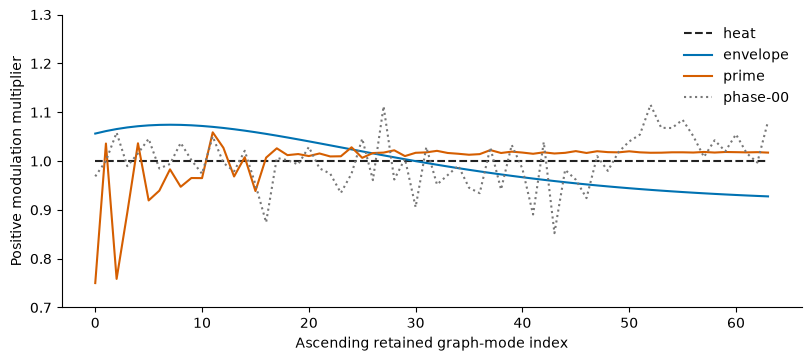

In [2]:
decoding = decoding_experiment()
print(decoding['config'])
names = decoding['waveforms']['names']
gates = decoding['waveforms']['multipliers']
np.testing.assert_allclose(gates.mean(axis=1), 1, atol=1e-14)
assert gates.min() >= 0.75 - 1e-14 and gates.max() <= 1.25 + 1e-14
np.testing.assert_allclose((decoding['gains']**2).sum(axis=1), (decoding['gains'][0]**2).sum(), atol=1e-12)
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
for name, colour, style in [('heat', '#222222', '--'), ('envelope', '#0072B2', '-'), ('prime', '#D55E00', '-'), ('phase-00', '#777777', ':')]:
    ax.plot(np.arange(64), gates[names.index(name)], color=colour, linestyle=style, label=name)
ax.set(xlabel='Ascending retained graph-mode index', ylabel='Positive modulation multiplier', ylim=(0.7, 1.3))
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
display(fig)
plt.close(fig)


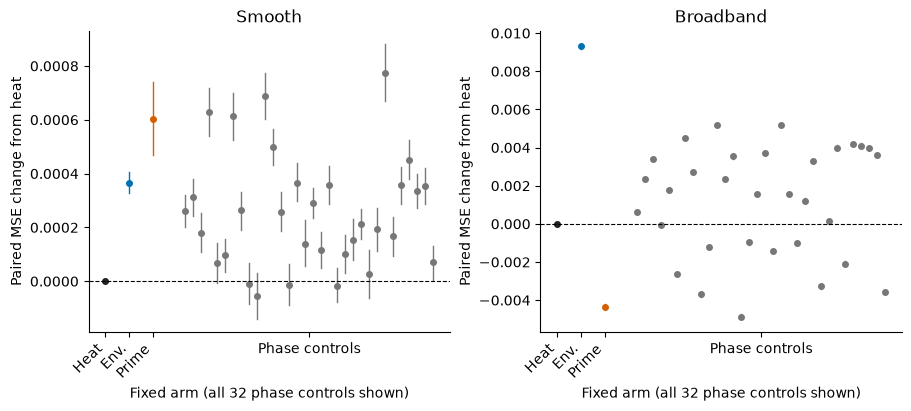

| Regime | Arm | MSE | Delta vs heat [95% interval] | Graph-weighted error |
|---|---|---:|---:|---:|
| smooth | heat | 0.061151 | +0.000000 [+0.000000, +0.000000] | 0.026394 |
| smooth | envelope | 0.061516 | +0.000365 [+0.000326, +0.000405] | 0.025599 |
| smooth | prime | 0.061754 | +0.000603 [+0.000470, +0.000739] | 0.027046 |
| smooth | phase-00 | 0.061412 | +0.000261 [+0.000201, +0.000320] | 0.026332 |
| smooth | phase-01 | 0.061462 | +0.000311 [+0.000243, +0.000378] | 0.026207 |
| smooth | phase-02 | 0.061330 | +0.000179 [+0.000107, +0.000253] | 0.026192 |
| smooth | phase-03 | 0.061780 | +0.000629 [+0.000539, +0.000719] | 0.026414 |
| smooth | phase-04 | 0.061217 | +0.000066 [-0.000005, +0.000144] | 0.026405 |
| smooth | phase-05 | 0.061248 | +0.000097 [+0.000035, +0.000156] | 0.026724 |
| smooth | phase-06 | 0.061764 | +0.000613 [+0.000525, +0.000698] | 0.026010 |
| smooth | phase-07 | 0.061414 | +0.000263 [+0.000192, +0.000332] | 0.026298 |
| smooth | phase-08 | 0.061139 | -0.000012 [-0.000086, +0.000068] | 0.026896 |
| smooth | phase-09 | 0.061096 | -0.000055 [-0.000139, +0.000032] | 0.026723 |
| smooth | phase-10 | 0.061838 | +0.000687 [+0.000602, +0.000772] | 0.025928 |
| smooth | phase-11 | 0.061651 | +0.000501 [+0.000433, +0.000565] | 0.026170 |
| smooth | phase-12 | 0.061407 | +0.000256 [+0.000186, +0.000332] | 0.026229 |
| smooth | phase-13 | 0.061136 | -0.000014 [-0.000088, +0.000064] | 0.026994 |
| smooth | phase-14 | 0.061516 | +0.000366 [+0.000300, +0.000439] | 0.026530 |
| smooth | phase-15 | 0.061291 | +0.000140 [+0.000058, +0.000228] | 0.026461 |
| smooth | phase-16 | 0.061441 | +0.000290 [+0.000234, +0.000346] | 0.026103 |
| smooth | phase-17 | 0.061266 | +0.000116 [+0.000049, +0.000183] | 0.026679 |
| smooth | phase-18 | 0.061508 | +0.000358 [+0.000287, +0.000427] | 0.026006 |
| smooth | phase-19 | 0.061134 | -0.000017 [-0.000077, +0.000048] | 0.026419 |
| smooth | phase-20 | 0.061252 | +0.000101 [+0.000030, +0.000171] | 0.026717 |
| smooth | phase-21 | 0.061305 | +0.000154 [+0.000079, +0.000230] | 0.026450 |
| smooth | phase-22 | 0.061363 | +0.000212 [+0.000155, +0.000270] | 0.026150 |
| smooth | phase-23 | 0.061176 | +0.000025 [-0.000061, +0.000116] | 0.026904 |
| smooth | phase-24 | 0.061346 | +0.000195 [+0.000114, +0.000272] | 0.026573 |
| smooth | phase-25 | 0.061924 | +0.000773 [+0.000671, +0.000880] | 0.026041 |
| smooth | phase-26 | 0.061319 | +0.000168 [+0.000095, +0.000239] | 0.026646 |
| smooth | phase-27 | 0.061507 | +0.000356 [+0.000288, +0.000425] | 0.026069 |
| smooth | phase-28 | 0.061603 | +0.000452 [+0.000380, +0.000524] | 0.026015 |
| smooth | phase-29 | 0.061486 | +0.000335 [+0.000272, +0.000397] | 0.026123 |
| smooth | phase-30 | 0.061505 | +0.000354 [+0.000288, +0.000422] | 0.026090 |
| smooth | phase-31 | 0.061221 | +0.000070 [+0.000006, +0.000132] | 0.026826 |
| smooth | projection | 0.128377 | +0.067226 [+0.066568, +0.067881] | 0.097420 |
| smooth | noisy | 0.252259 | +0.191109 [+0.189898, +0.192240] | 0.502242 |
| broadband | heat | 0.684918 | +0.000000 [+0.000000, +0.000000] | 1.812352 |
| broadband | envelope | 0.694222 | +0.009305 [+0.009193, +0.009409] | 1.822058 |
| broadband | prime | 0.680581 | -0.004336 [-0.004479, -0.004181] | 1.808342 |
| broadband | phase-00 | 0.685524 | +0.000607 [+0.000506, +0.000708] | 1.811045 |
| broadband | phase-01 | 0.687263 | +0.002345 [+0.002230, +0.002469] | 1.812572 |
| broadband | phase-02 | 0.688298 | +0.003381 [+0.003273, +0.003496] | 1.815458 |
| broadband | phase-03 | 0.684869 | -0.000049 [-0.000164, +0.000067] | 1.810327 |
| broadband | phase-04 | 0.686708 | +0.001790 [+0.001672, +0.001904] | 1.815194 |
| broadband | phase-05 | 0.682269 | -0.002648 [-0.002755, -0.002536] | 1.808735 |
| broadband | phase-06 | 0.689419 | +0.004502 [+0.004378, +0.004628] | 1.815481 |
| broadband | phase-07 | 0.687641 | +0.002723 [+0.002616, +0.002831] | 1.815747 |
| broadband | phase-08 | 0.681217 | -0.003700 [-0.003821, -0.003585] | 1.808970 |
| broadband | phase-09 | 0.683696 | -0.001221 [-0.001335, -0.001104] | 1.812547 |
| broadband | phase-10 | 0.690107 | +0.005190 [+0.005068, +0.005310] | 1.815599 |
| broadband | phase-11 | 0.687260 | +0.002342 [+0.002237, +0.002451] | 1.812518 |
| broadband | phase-12 | 0.688452 | +0.003534 [+0.003427, +0.003643] | 1.816645 |
| broadband | phase-13 | 0.680058 | -0.004859 [-0.004973, -0.004741] | 1.807584 |
| broadband | phase-14 | 0.683942 | -0.000975 [-0.001086, -0.000864] | 1.810089 |
| broadband | phase-15 | 0.686487 | +0.001570 [+0.001458, +0.001680] | 1.814966 |
| broadband | phase-16 | 0.688644 | +0.003727 [+0.003624, +0.003830] | 1.815150 |
| broadband | phase-17 | 0.683520 | -0.001398 [-0.001500, -0.001300] | 1.811794 |
| broadband | phase-18 | 0.690105 | +0.005187 [+0.005072, +0.005291] | 1.817661 |
| broadband | phase-19 | 0.686502 | +0.001584 [+0.001482, +0.001686] | 1.815184 |
| broadband | phase-20 | 0.683915 | -0.001003 [-0.001114, -0.000896] | 1.812602 |
| broadband | phase-21 | 0.686132 | +0.001214 [+0.001099, +0.001332] | 1.814826 |
| broadband | phase-22 | 0.688187 | +0.003270 [+0.003167, +0.003372] | 1.814888 |
| broadband | phase-23 | 0.681641 | -0.003276 [-0.003398, -0.003146] | 1.809494 |
| broadband | phase-24 | 0.685046 | +0.000128 [+0.000017, +0.000241] | 1.813795 |
| broadband | phase-25 | 0.688904 | +0.003986 [+0.003859, +0.004114] | 1.813766 |
| broadband | phase-26 | 0.682834 | -0.002084 [-0.002194, -0.001971] | 1.808753 |
| broadband | phase-27 | 0.689114 | +0.004196 [+0.004085, +0.004311] | 1.816043 |
| broadband | phase-28 | 0.689024 | +0.004107 [+0.003998, +0.004220] | 1.814392 |
| broadband | phase-29 | 0.688899 | +0.003982 [+0.003873, +0.004096] | 1.815982 |
| broadband | phase-30 | 0.688550 | +0.003632 [+0.003523, +0.003736] | 1.814970 |
| broadband | phase-31 | 0.681324 | -0.003594 [-0.003699, -0.003490] | 1.807932 |
| broadband | projection | 0.625163 | -0.059755 [-0.061291, -0.058174] | 1.717314 |
| broadband | noisy | 0.250873 | -0.434045 [-0.438254, -0.429528] | 0.497726 |


Descriptive phase ranks (not p-values): {'smooth': {'prime_rank_among_phase_controls': 29, 'out_of': 33, 'phase_mse_min': 0.0610956126665412, 'phase_mse_max': 0.06192401749738972}, 'broadband': {'prime_rank_among_phase_controls': 2, 'out_of': 33, 'phase_mse_min': 0.6800581036338884, 'phase_mse_max': 0.6901073992108764}}
Exporter parity: all measured rows, raw outcomes, input and source hashes match.


In [3]:
fig = decoding_figure(decoding)
display(fig)
plt.close(fig)
table = '| Regime | Arm | MSE | Delta vs heat [95% interval] | Graph-weighted error |\n|---|---|---:|---:|---:|\n'
for r in decoding['rows']:
    table += f"| {r['regime']} | {r['arm']} | {r['mse']:.6f} | {r['delta_mse']:+.6f} [{r['ci_low']:+.6f}, {r['ci_high']:+.6f}] | {r['graph_error']:.6f} |\n"
display(Markdown(table))
print('Descriptive phase ranks (not p-values):', decoding['phase_ranks'])
verify_exported_result(decoding, 'decoding')
print('Exporter parity: all measured rows, raw outcomes, input and source hashes match.')


## Why a shared clock is insufficient

For a fixed graph, exact evolution obeys

$$\dot a(t)=-g(t)La(t),\qquad a(T)=\exp\!\left(-L\int_0^Tg(t)dt\right)a(0).$$

Equal integrated time gives identical endpoints. Euler differences vanish under refinement; they are not evidence that prime timing improves the exact linear operator. This does not rule out a nonlinear decoder or mode-dependent gains.

In [4]:
for steps in (64, 256, 1024):
    rows = [r for r in decoding['clock'] if r['steps'] == steps]
    print(steps, 'steps | max exact error', max(r['exact_error'] for r in rows), '| max Euler error', max(r['euler_error'] for r in rows))
assert max(r['exact_error'] for r in decoding['clock']) < 1e-12


64 steps | max exact error 2.886579864025407e-15 | max Euler error 0.004263097009129219
256 steps | max exact error 1.3655743202889425e-14 | max Euler error 0.0010615741717139027
1024 steps | max exact error 5.46229728115577e-14 | max Euler error 0.0002651310909723703


## Actual v2 neural integration

The VAE now creates the graph decoder **before** optimiser construction. Each graph block multiplies its learned mode gate by the fixed experimental gains. The test below checks numerical parity, output sensitivity, registered parameters and a real SGD update. The dispersion vector is an explicit synthetic fixture, not an ArrowSpace-estimated value. Images are random tensors; their loss is only an execution check.

In [5]:
nu, U = path_basis(128)
prior = ArrowSpacePrior(torch.tensor((U * nu) @ U.T), torch.tensor(U[:, :64]), torch.tensor(nu[:64]), torch.linspace(0, 1, 128))
torch.manual_seed(3407)
vae = SpectralVAE(prior=prior, feature_dim=128, base_channels=8, gate_kind='prime')
actual = vae.decoder.spectral_gate().detach().numpy()
assert actual.dtype == np.float32
np.testing.assert_allclose(actual, decoding['gains'][names.index('prime')], rtol=2e-6, atol=1e-7)
print('Float32 gain maximum absolute discrepancy:', np.max(np.abs(actual - decoding['gains'][names.index('prime')])))
ids = {id(p) for p in vae.parameters()}
optimizer = torch.optim.SGD(vae.parameters(), lr=1e-3)
images = torch.randn(4, 3, 16, 16)
before = vae.decoder.wave_block_1.gate.weight.detach().clone()
z, A, chart, reconstruction = vae(images, prior)
loss = (reconstruction - images).square().mean() + 1e-3 * vae.kl_loss()
loss.backward()
gradient = vae.decoder.wave_block_1.gate.weight.grad
assert gradient is not None and torch.isfinite(gradient).all() and gradient.abs().sum() > 0
optimizer.step()
assert ids == {id(p) for p in vae.parameters()}
assert not torch.equal(before, vae.decoder.wave_block_1.gate.weight)
assert reconstruction.shape == images.shape
assert all(not b.requires_grad and b.grad is None for b in prior.buffers())
vae.eval()
with torch.no_grad():
    prime_output = vae.decode(z.detach(), chart.detach(), prior)
    vae.decoder.spectral_gate = ModalGate(prior, 'heat')
    heat_output = vae.decode(z.detach(), chart.detach(), prior)
    vae.decoder.spectral_gate = ModalGate(prior, 'prime')
sensitivity = (prime_output - heat_output).abs().max().item()
assert sensitivity > 1e-7
print('Fixed-latent prime/heat maximum output difference:', sensitivity)
print('Numeric parity, frozen prior, output sensitivity and SGD gradient/update checks passed.')
print('Synthetic execution-check loss:', loss.item())


Float32 gain maximum absolute discrepancy: 1.1745939199059308e-07


Fixed-latent prime/heat maximum output difference: 0.0017673671245574951
Numeric parity, frozen prior, output sensitivity and SGD gradient/update checks passed.
Synthetic execution-check loss: 1.0525304079055786


## How to read the result

Negative paired MSE change favours that arm. A prime improvement over heat alone is insufficient: compare all phase controls. The prime-rank diagnostic is not a significance test. Results are conditional on a single graph, two synthetic generators and one chosen mapping from log-prime scale to graph modes.

The full study exporter writes raw per-signal outcomes, hashes, plots and manuscript tables: `uv run python scripts/run_prime_study.py`. Real-image encoding and generative quality require a separately trained, held-out experiment. No RH truth claim follows from this notebook.